# Untitled Notebook

In [1]:
name = "Ada"

numbers = [1, 2, 3, 4, 5]

average = sum(numbers) / len(numbers)



print(f"Hello, {name}!")

print(f"Average: {average}")

Hello, Ada!
Average: 3.0


In [1]:
import pandas as pd

# Illustrative sample data only; these are not live market prices.
stocks = pd.DataFrame([
    {"Company": "Apple", "Ticker": "AAPL", "Previous Close": 228.50, "Close": 231.20, "Volume": 45600000},
    {"Company": "Microsoft", "Ticker": "MSFT", "Previous Close": 416.30, "Close": 412.80, "Volume": 19200000},
    {"Company": "NVIDIA", "Ticker": "NVDA", "Previous Close": 138.90, "Close": 141.50, "Volume": 31500000},
    {"Company": "Amazon", "Ticker": "AMZN", "Previous Close": 218.40, "Close": 220.10, "Volume": 28400000},
])

stocks["Change (%)"] = ((stocks["Close"] - stocks["Previous Close"]) / stocks["Previous Close"] * 100).round(2)
display(stocks)

,Company,Ticker,Previous Close,Close,Volume,Change (%)
0,Apple,AAPL,228.5,231.2,45600000,1.18
1,Microsoft,MSFT,416.3,412.8,19200000,-0.84
2,NVIDIA,NVDA,138.9,141.5,31500000,1.87
3,Amazon,AMZN,218.4,220.1,28400000,0.78


In [2]:
display(stocks[["Close", "Change (%)", "Volume"]].describe().round(2))

average_change = stocks["Change (%)"].mean()
best = stocks.loc[stocks["Change (%)"].idxmax()]
worst = stocks.loc[stocks["Change (%)"].idxmin()]
average_volume = stocks["Volume"].mean()

print(f"Average daily change: {average_change:.2f}%")
print(f"Average trading volume: {average_volume:,.0f} shares")
print(f"Top performer: {best['Company']} ({best['Ticker']}) at {best['Change (%)']:.2f}%")
print(f"Lowest performer: {worst['Company']} ({worst['Ticker']}) at {worst['Change (%)']:.2f}%")

,Close,Change (%),Volume
count,4.00,4.00,4.00
mean,251.40,0.75,31175000.00
std,114.77,1.15,10943605.44
min,141.50,-0.84,19200000.00
25%,200.45,0.38,26100000.00
50%,225.65,0.98,29950000.00
75%,276.60,1.35,35025000.00
max,412.80,1.87,45600000.00


Average daily change: 0.75%
Average trading volume: 31,175,000 shares
Top performer: NVIDIA (NVDA) at 1.87%
Lowest performer: Microsoft (MSFT) at -0.84%


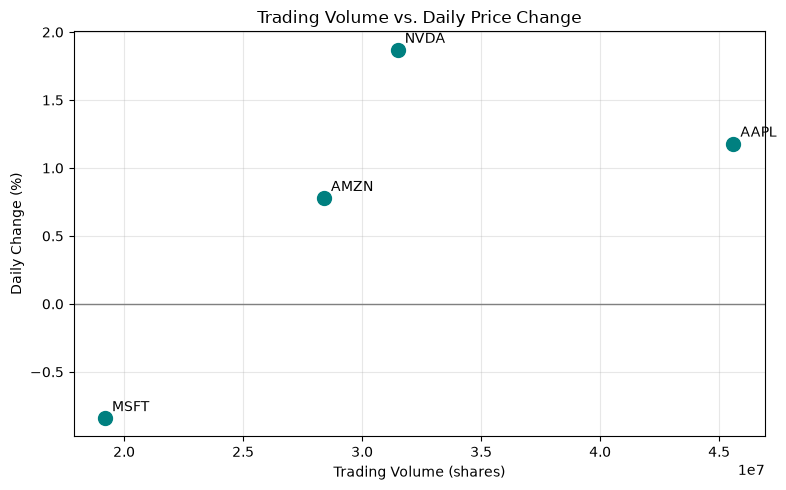

In [2]:
import matplotlib.pyplot as plt

ax = stocks.plot.scatter(
    x="Volume",
    y="Change (%)",
    figsize=(8, 5),
    s=100,
    color="teal",
    title="Trading Volume vs. Daily Price Change",
)

for _, stock in stocks.iterrows():
    ax.annotate(
        stock["Ticker"],
        (stock["Volume"], stock["Change (%)"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.axhline(0, color="gray", linewidth=1)
ax.set_xlabel("Trading Volume (shares)")
ax.set_ylabel("Daily Change (%)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()